# RAG Hallucination Detector (RAGTruth)

**Problem.** In a RAG system, an LLM answers using retrieved documents (the *context*). Sometimes the answer contains claims that the context doesn't support. These are **hallucinations**.

**Goal.** Given the *context* and the LLM *response*, flag the sentences that are hallucinated and give an overall risk score.

**Dataset.** [RAGTruth](https://github.com/ParticleMedia/RAGTruth): 17,790 responses from 6 LLMs (GPT-4, GPT-3.5, Llama-2 7B/13B/70B, Mistral-7B) across 3 tasks (QA, Summary, Data-to-text). Humans marked the exact character spans that are hallucinated.

**Pipeline.** Download data → SQLite database → split responses into sentences → engineer context-overlap features → train and compare 3 classifiers → evaluate on the held-out test set → Streamlit web app.

👉 Run all cells (**Run → Run All**). Paste your Gemini API key when asked (step 2). The last cell opens the app in your browser.

## 1. Install requirements

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 2. Your Gemini API key (only for the *Ask Gemini* mode)
Everyone uses **their own** free key from https://aistudio.google.com/apikey. When this cell asks, paste it and press Enter. It is saved on your computer in `.streamlit/secrets.toml` and asked only once. Press Enter without a key to skip: everything else still works.

In [ ]:
import getpass, json, os
from pathlib import Path

secrets = Path(".streamlit/secrets.toml")
if os.environ.get("GEMINI_API_KEY") or (secrets.exists() and "GEMINI_API_KEY" in secrets.read_text()):
    print("✅ Gemini API key found. To change it, edit or delete .streamlit/secrets.toml")
else:
    try:
        key = getpass.getpass("Paste your Gemini API key and press Enter (or just press Enter to skip): ").strip()
    except Exception:  # no input box available (e.g. running headless)
        key = ""
    if key:
        secrets.parent.mkdir(exist_ok=True)
        secrets.write_text(f"GEMINI_API_KEY = {json.dumps(key)}\n")
        print("✅ Saved to .streamlit/secrets.toml (only on this computer, never shared or committed).")
    else:
        print("Skipped. Everything works except 'Ask Gemini'. Re-run this cell any time to add a key.")

## 3. Download the dataset and load it into SQLite
`backend.build_db()` downloads `response.jsonl` and `source_info.jsonl` from GitHub and loads them into `ragtruth.db` with 4 tables:
- `sources`: the retrieved context for each passage
- `responses`: LLM answers + human hallucination labels (foreign key → sources)
- `runs`: model evaluation results
- `predictions`: every detection made from the web app

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import backend as b

b.build_db()
b.query("SELECT name FROM sqlite_master WHERE type='table'")

downloading response.jsonl


downloading source_info.jsonl


,name
0,sources
1,responses
2,runs
3,sqlite_sequence
4,predictions


In [3]:
b.query("""SELECT r.id, s.task_type, r.model, r.split, r.hallucinated, substr(r.response,1,120) AS response
           FROM responses r JOIN sources s USING(source_id) LIMIT 5""")

,id,task_type,model,split,hallucinated,response
0,0,Summary,gpt-4-0613,train,0,The Anne Frank House has revealed that Anne Fr...
1,1,Summary,gpt-3.5-turbo-0613,train,0,New research released by the Anne Frank House ...
2,2,Summary,mistral-7B-instruct,train,1,New research conducted by the Anne Frank House...
3,3,Summary,llama-2-7b-chat,train,1,Here is a summary of the article in 115 words ...
4,4,Summary,llama-2-13b-chat,train,0,"Seventy years ago, Anne Frank died of typhus i..."


## 4. Exploratory data analysis

In [4]:
stats = b.query("""SELECT COUNT(*) responses, SUM(hallucinated) hallucinated,
                     ROUND(AVG(hallucinated)*100,1) AS pct_hallucinated, (SELECT COUNT(*) FROM sources) sources
                     FROM responses""")
stats

,responses,hallucinated,pct_hallucinated,sources
0,17790,7664,43.1,2965


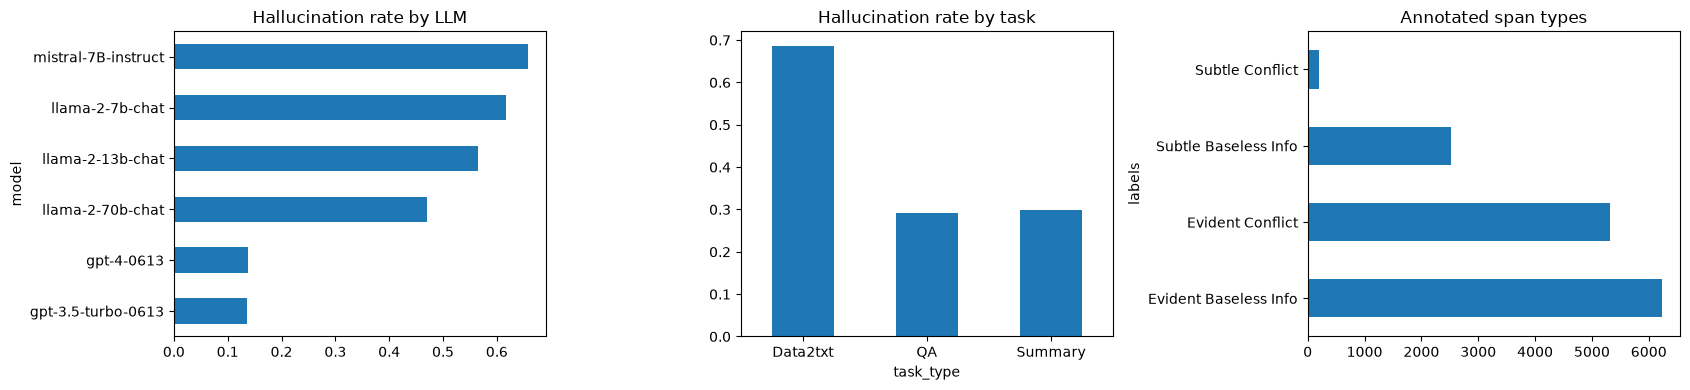

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
b.query("SELECT model, AVG(hallucinated) rate FROM responses GROUP BY model ORDER BY rate").plot.barh(x="model", y="rate", ax=ax[0], legend=False, title="Hallucination rate by LLM")
b.query("SELECT task_type, AVG(hallucinated) rate FROM responses JOIN sources USING(source_id) GROUP BY task_type").plot.bar(x="task_type", y="rate", ax=ax[1], legend=False, title="Hallucination rate by task", rot=0)
spans = b.query("SELECT labels FROM responses WHERE hallucinated=1").labels.apply(json.loads).explode().dropna()
spans.apply(lambda l: l["label_type"]).value_counts().plot.barh(ax=ax[2], title="Annotated span types")
plt.tight_layout(); plt.show()

**Observations:** smaller open models (Llama-2-7B, Mistral) hallucinate far more than GPT-4. Data-to-text (writing about a business from JSON) is the hardest task. Most hallucinations are *baseless info*: facts added that aren't in the context.

## 5. Train / dev / test split
RAGTruth ships a train/test split. We carve a **dev** set out of train, grouped by `source_id` (all 6 answers to one passage go to the same split, so there's no leakage). Refusals and truncated answers are dropped.

In [6]:
df = b.load_dataset()
df.split.value_counts()

split
train    13531
test      2675
dev       1411
Name: count, dtype: int64

## 6. Feature engineering (sentence level)
Each response is split into sentences. A sentence is labelled **1** if it overlaps a human-annotated hallucination span. For each sentence we compute features **against the context**:

| Feature | Intuition |
|---|---|
| `novel_word_ratio`, `novel_words` | content words that never appear in the context |
| `novel_numbers`, `novel_number_ratio` | numbers/dates not in the context (invented facts) |
| `novel_capitals` | capitalised names not in the context (invented entities) |
| `bigram_overlap`, `trigram_overlap` | how much of the sentence is copied from the context |
| `n_words`, `position`, `is_last` | length and position (LLMs often add unsupported stuff at the end) |

In [7]:
sent = b.sentence_table(df)
print(sent.groupby("split").label.agg(count="count", hallucinated_rate="mean"))
sent.head()

        count  hallucinated_rate
split                           
dev     11092           0.116931
test    20182           0.082499
train  110264           0.107986


,response_id,split,task_type,label,n_words,novel_word_ratio,novel_words,novel_numbers,novel_number_ratio,novel_capitals,bigram_overlap,trigram_overlap,position,is_last
0,0,train,Summary,0,24,0.187500,3,0,0.0,0,0.695652,0.500000,0.000000,0
1,0,train,Summary,0,29,0.062500,1,0,0.0,0,0.357143,0.111111,0.333333,0
2,0,train,Summary,0,28,0.210526,4,0,0.0,1,0.407407,0.192308,0.666667,0
3,0,train,Summary,0,27,0.083333,1,0,0.0,0,0.384615,0.160000,1.000000,1
4,1,train,Summary,0,26,0.111111,2,0,0.0,0,0.840000,0.625000,0.000000,0


In [8]:
sent[sent.split=="train"].groupby("label")[b.FEATURES].mean().T.rename(columns={0: "grounded", 1: "hallucinated"}).round(3)

label,grounded,hallucinated
n_words,16.081,17.513
novel_word_ratio,0.295,0.511
novel_words,3.048,5.549
novel_numbers,0.092,0.305
novel_number_ratio,0.056,0.140
novel_capitals,0.080,0.264
bigram_overlap,0.345,0.147
trigram_overlap,0.211,0.060
position,0.491,0.560
is_last,0.123,0.122


Hallucinated sentences have more novel words/numbers/names and much lower n-gram overlap with the context, so these features carry real signal.

## 7. Train and compare models
Three classifiers: **Logistic Regression**, **Random Forest**, **Gradient Boosting**. Class weights are balanced (only ~11% of sentences are hallucinated). The decision threshold is tuned for F1 on dev, and the **best model is also chosen by dev F1**. The untouched **test** split is only used to report the final numbers. The best model is saved to `model.joblib` and all results are written to the `runs` table.

In [9]:
results, best = b.train(sent)
print("Best model:", best)
results.set_index("model").round(3)

Best model: Gradient Boosting


,threshold,dev_f1,accuracy,precision,recall,f1,roc_auc,resp_accuracy,resp_precision,resp_recall,resp_f1,resp_roc_auc
model,,,,,,,,,,,,
Logistic Regression,0.62,0.352,0.800,0.211,0.522,0.301,0.771,0.676,0.526,0.830,0.644,0.781
Random Forest,0.59,0.382,0.826,0.243,0.524,0.332,0.786,0.692,0.543,0.801,0.647,0.796
Gradient Boosting,0.63,0.392,0.816,0.240,0.571,0.338,0.797,0.693,0.542,0.828,0.655,0.800


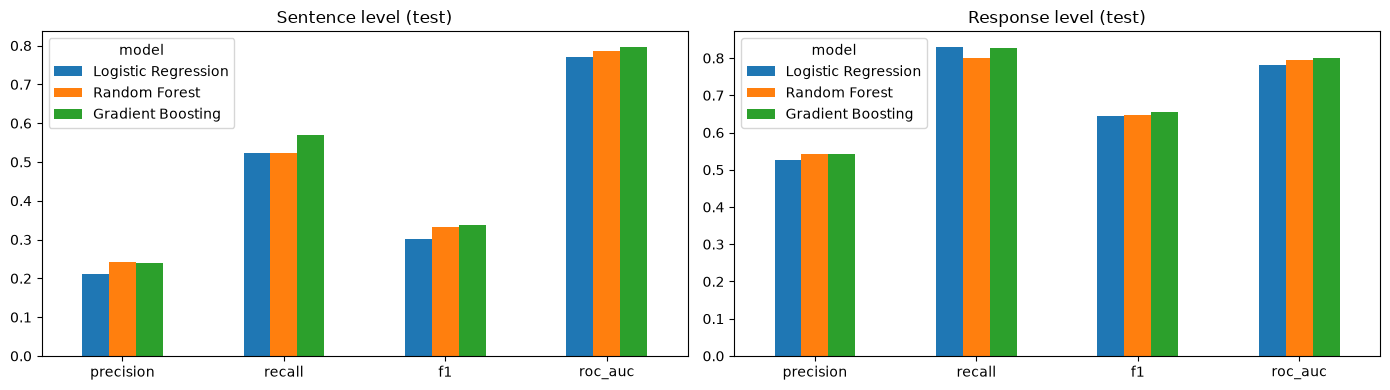

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cols = ["precision", "recall", "f1", "roc_auc"]
results.set_index("model")[cols].T.plot.bar(ax=ax[0], rot=0, title="Sentence level (test)")
results.set_index("model")[["resp_" + c for c in cols]].T.rename(index=lambda c: c[5:]).plot.bar(ax=ax[1], rot=0, title="Response level (test)")
plt.tight_layout(); plt.show()

**Response level:** a response is flagged if any of its sentences is flagged. That's the practical question: *should I trust this answer?*

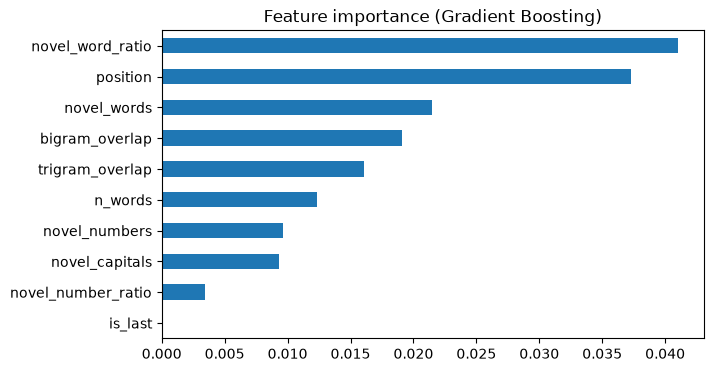

In [11]:
bundle = b.load_model()
if hasattr(bundle["model"], "feature_importances_"):
    imp = pd.Series(bundle["model"].feature_importances_, b.FEATURES)
else:
    from sklearn.inspection import permutation_importance
    te = sent[sent.split == "test"].sample(5000, random_state=0)
    imp = pd.Series(permutation_importance(bundle["model"], te[b.FEATURES], te.label, scoring="roc_auc", n_repeats=3, random_state=0).importances_mean, b.FEATURES)
imp.sort_values().plot.barh(title=f"Feature importance ({bundle['name']})", figsize=(7, 4)); plt.show()

## 8. Try the detector

In [12]:
ctx = "The Eiffel Tower is in Paris. It was completed in 1889 and is 330 metres tall."
resp = "The Eiffel Tower is in Paris and was completed in 1889. It was designed by Leonardo da Vinci."
r = b.detect(ctx, resp, log=False)
print(r["verdict"], "| risk score:", round(r["score"], 2))
pd.DataFrame(r["sentences"])[["text", "prob", "flagged", "unsupported_words"]]

Likely hallucinated | risk score: 0.85


,text,prob,flagged,unsupported_words
0,The Eiffel Tower is in Paris and was completed...,0.063307,False,[]
1,It was designed by Leonardo da Vinci.,0.845054,True,"[designed, Leonardo, da, Vinci]"


## 9. Launch the web app 🚀
Starts Streamlit on http://localhost:8501 and opens it in your browser. This cell keeps running while the app is up; interrupt it to stop the app. Tabs: **Detector** (write your own context + response, load a demo scenario, let **Gemini** generate the answer for the model to check (needs a free API key), or pick a real test example and compare with the human labels), **Dataset**, **Model Performance**, **History** (every detection is stored in SQLite).

In [ ]:
import socket, subprocess, sys, time, urllib.request, webbrowser

def port_free(p):
    with socket.socket() as s:
        return s.connect_ex(("localhost", p)) != 0

port = next(p for p in range(8501, 8600) if port_free(p))  # 8501, or the next free port if it's taken
url = f"http://localhost:{port}"
log = open("streamlit.log", "w")
# headless: skips Streamlit's first-run "enter your email" prompt, which would block inside a notebook
app = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", str(port),
                        "--server.headless", "true"], stdout=log, stderr=subprocess.STDOUT)
for _ in range(60):
    time.sleep(1)
    try:
        urllib.request.urlopen(url + "/_stcore/health", timeout=2)
        break
    except OSError:
        if app.poll() is not None:
            break
if app.poll() is None:
    webbrowser.open(url)
    print(f"✅ App running at {url} (opened in your browser).")
    print("To stop it, press the ■ Stop / Interrupt button on this cell.")
    try:
        app.wait()
    except KeyboardInterrupt:
        app.terminate()
        print("App stopped.")
else:
    print("❌ The app did not start. Last lines of streamlit.log:")
    print(open("streamlit.log").read()[-2000:])

## 10. Limitations and future work
- The model uses **lexical** features, so a paraphrase that's correct can look 'novel', and a contradiction that reuses context words (e.g. swapped numbers) can look grounded.
- Upgrade path: fine-tune a transformer token classifier (e.g. ModernBERT / DeBERTa) on `[context] [SEP] [response]` for word-level spans, or add an NLI model score as a feature.